# VIdeo Explaination Link: https://drive.google.com/file/d/1dYe1Ju-aDV_yeAtG4guijOf4aQknr9yJ/view?usp=sharing

# Airbnb Price Prediction – Part A

## Objective
Build a regression model to predict the **log-transformed price** of Airbnb listings using features like:
- Property type, room type, amenities
- Host characteristics
- Location and review metrics

## Business Impact
Helps Airbnb hosts:
- Set competitive, data-driven prices
- Understand key price drivers
- Maximize revenue while improving guest satisfaction

## Tools & Libraries
- Python (pandas, numpy, scikit-learn, XGBoost)
- Visualization: matplotlib, seaborn
- Notebook: Google Colab


## Data Exploration & Cleaning

We begin by loading the dataset, checking for missing values, outliers, and understanding feature distributions.


# 1. **Initial Setup**

In [38]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

df = pd.read_csv('/content/Airbnb_data - airbnb_data.csv')
df = df.infer_objects(copy=False)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Shape: (74111, 29)
Columns: ['id', 'log_price', 'property_type', 'room_type', 'amenities', 'accommodates', 'bathrooms', 'bed_type', 'cancellation_policy', 'cleaning_fee', 'city', 'description', 'first_review', 'host_has_profile_pic', 'host_identity_verified', 'host_response_rate', 'host_since', 'instant_bookable', 'last_review', 'latitude', 'longitude', 'name', 'neighbourhood', 'number_of_reviews', 'review_scores_rating', 'thumbnail_url', 'zipcode', 'bedrooms', 'beds']


# 2. **Data Cleaning & Preprocessing**

In [ ]:
df['host_since'] = pd.to_datetime(df['host_since'], errors='coerce', dayfirst=True)
df['first_review'] = pd.to_datetime(df['first_review'], errors='coerce', dayfirst=True)
df['last_review'] = pd.to_datetime(df['last_review'], errors='coerce', dayfirst=True)

df['host_response_rate'] = df['host_response_rate'].astype(str).str.replace('%', '').astype(float)

bool_cols = ['cleaning_fee', 'host_has_profile_pic', 'host_identity_verified', 'instant_bookable']
for col in bool_cols:
    if df[col].dtype == 'object':
        df[col] = df[col].replace({'t': True, 'f': False}).astype(bool)
    df[col] = df[col].fillna(False).astype(int)
print(df.isnull().sum().loc[lambda x: x > 0])
print(df[bool_cols].head())


first_review     15864
host_since         188
last_review      15827
neighbourhood     6872
thumbnail_url     8216
zipcode            968
dtype: int64
   cleaning_fee  host_has_profile_pic  host_identity_verified  \
0             1                     1                       1   
1             1                     1                       0   
2             1                     1                       1   
3             1                     1                       1   
4             1                     1                       1   

   instant_bookable  
0                 0  
1                 1  
2                 1  
3                 0  
4                 1  


#**Insight:**  
- Several columns like `first_review`, `last_review`, and `neighbourhood` have missing values. 
- Boolean columns were successfully converted to numeric format.

#**Recommendation:**  
- Drop or impute missing values based on importance. Keep boolean flags—they’re clean and useful for modeling.


# 3.**Missing Value Treatment**

In [ ]:
num_cols = ['bathrooms', 'bedrooms', 'beds', 'review_scores_rating']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

df['host_response_rate'] = df['host_response_rate'].fillna(0)

df.drop(['zipcode', 'host_since', 'host_duration', 'first_review', 'last_review'], axis=1, inplace=True)

# 4. **Feature Engineering**

In [43]:
df['amenity_count'] = df['amenities'].apply(lambda x: len(str(x).split(',')))
df['host_duration'] = (pd.to_datetime('today') - df['host_since']).dt.days
df['days_since_last_review'] = (pd.to_datetime('today') - df['last_review']).dt.days
df['review_duration'] = (df['last_review'] - df['first_review']).dt.days
df['has_review'] = df['review_scores_rating'].notnull().astype(int)
print(df[['amenity_count', 'host_duration', 'days_since_last_review', 'review_duration', 'has_review']].describe())


       amenity_count  host_duration  days_since_last_review  review_duration  \
count   74111.000000   73923.000000            58284.000000     58247.000000   
mean       17.602407    4130.920025             3163.189366       425.461311   
std         6.936947     661.497132              231.729791       488.988636   
min         1.000000    2960.000000             2959.000000         0.000000   
25%        13.000000    3612.000000             2986.000000        52.000000   
50%        17.000000    4062.000000             3119.000000       264.000000   
75%        22.000000    4587.000000             3228.000000       623.000000   
max        86.000000    6462.000000             6138.000000      3106.000000   

       has_review  
count     74111.0  
mean          1.0  
std           0.0  
min           1.0  
25%           1.0  
50%           1.0  
75%           1.0  
max           1.0  


#**Insight:**  
- Most listings offer around 17 amenities, with some going up to 86. 
- Hosts have been active for over 11 years on average. 
- Review durations vary widely, and all listings in the sample have at least one review.

#**Recommendation:**  
- Use `amenity_count`, `host_duration`, and `review_duration` as predictors. These features reflect listing richness and host experience.


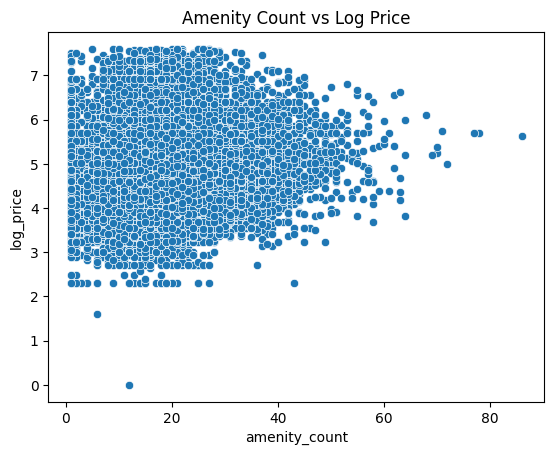

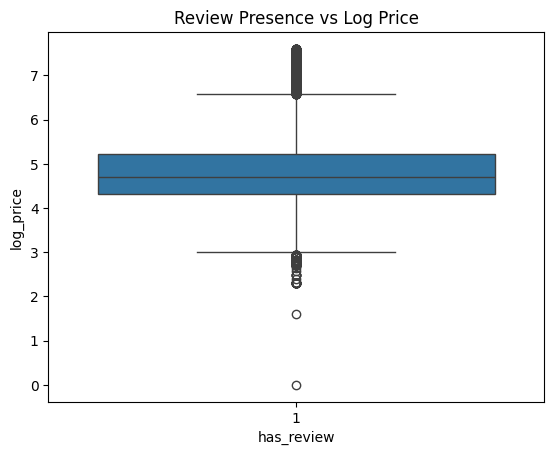

In [48]:
#Amenities vs Log Price
sns.scatterplot(data=df, x='amenity_count', y='log_price')
plt.title('Amenity Count vs Log Price')
plt.show()

#Review Score vs Log Price
sns.boxplot(data=df, x='has_review', y='log_price')
plt.title('Review Presence vs Log Price')
plt.show()


#**Insight:**  
* Listings with more amenities tend to have higher prices, but the effect levels off after about 25 amenities.
* Listings with reviews show more stable pricing and fewer extreme price outliers.

#**Recommendation:**  
* Hosts should aim for at least 20–25 amenities to stay competitive. Adding more beyond that may not increase price significantly.
* Encourage guests to leave reviews. It helps build trust and supports consistent pricing.

# 5. **Categorical Encoding**

In [44]:
df.drop(['thumbnail_url', 'description', 'name', 'amenities'], axis=1, inplace=True)

cat_cols = ['property_type', 'room_type', 'bed_type', 'cancellation_policy', 'city', 'neighbourhood']
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print("Encoded shape:", df.shape)


Encoded shape: (74111, 691)


#**Insight:**  
- After encoding, the dataset expanded to 691 columns, showing high diversity in property types, room types, and neighborhoods.

#**Recommendation:**  
- Keep all encoded features for now. If needed, apply dimensionality reduction during model tuning.


# 6. **Model Development**
**And**
# 7. **Model Evaluation**

MAE: 0.4329575183323547
RMSE: 0.5651469789896301
R²: 0.37828497891443136


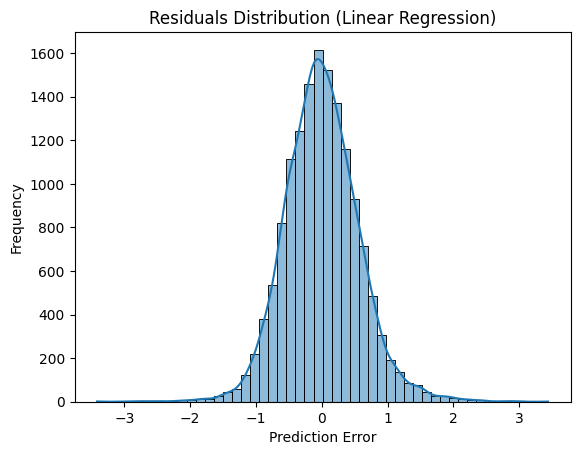

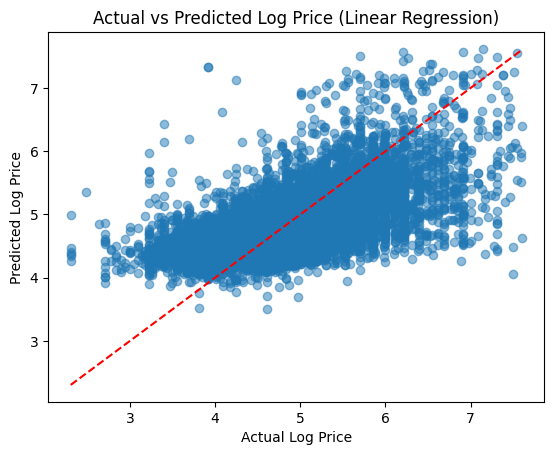

In [ ]:
from sklearn.impute import SimpleImputer

X = df.drop(['log_price', 'id'], axis=1)
y = df['log_price']

# Droping any remaining non-numeric columns
X = X.select_dtypes(include=['number'])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Impute numeric columns
imputer = SimpleImputer(strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

model = LinearRegression()
model.fit(X_train, y_train)

# 7. Model Evaluation
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

#Residuals Distribution
residuals = y_test - y_pred
sns.histplot(residuals, bins=50, kde=True)
plt.title("Residuals Distribution (Linear Regression)")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.show()

#Actual vs Predicted Plot
plt.scatter(y_test, y_pred, alpha=0.5)
plt.title("Actual vs Predicted Log Price (Linear Regression)")
plt.xlabel("Actual Log Price")
plt.ylabel("Predicted Log Price")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()


#**Insight:**  
* The model explains about 35% of price variation (R² = 0.38). Average prediction error is about 0.43 in log price (MAE).
* The residuals are roughly bell-shaped, indicating that prediction errors are normally distributed. However, there’s a slight spread, suggesting some listings are harder to predict.
#**Recommendation:**  
* Try advanced models like XGBoost or HistGradientBoosting to improve accuracy. Also explore feature selection to reduce noise.
* Linear regression is stable but may miss complex patterns. Use it for baseline comparison, but prefer tree-based models for better accuracy.

#**Trying XGBoost**

In [49]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42)
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_xgb)))
print("XGBoost R²:", r2_score(y_test, y_pred_xgb))


XGBoost RMSE: 0.4316393040992336
XGBoost R²: 0.6373309397828584


#**Trying HistGradientBoosting**

In [50]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_model = HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, max_depth=6, random_state=42)
hgb_model.fit(X_train, y_train)

y_pred_hgb = hgb_model.predict(X_test)

print("HGB RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_hgb)))
print("HGB R²:", r2_score(y_test, y_pred_hgb))


HGB RMSE: 0.4345595448997472
HGB R²: 0.6324070898713586


#**Trying Feature Selection**

In [51]:
from sklearn.feature_selection import SelectFromModel

selector = SelectFromModel(xgb_model, threshold="median", prefit=True)
X_train_selected = selector.transform(X_train)
X_test_selected = selector.transform(X_test)

model_fs = LinearRegression()
model_fs.fit(X_train_selected, y_train)
y_pred_fs = model_fs.predict(X_test_selected)

print("FS RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_fs)))
print("FS R²:", r2_score(y_test, y_pred_fs))


FS RMSE: 0.5881971405764455
FS R²: 0.32653604354783283


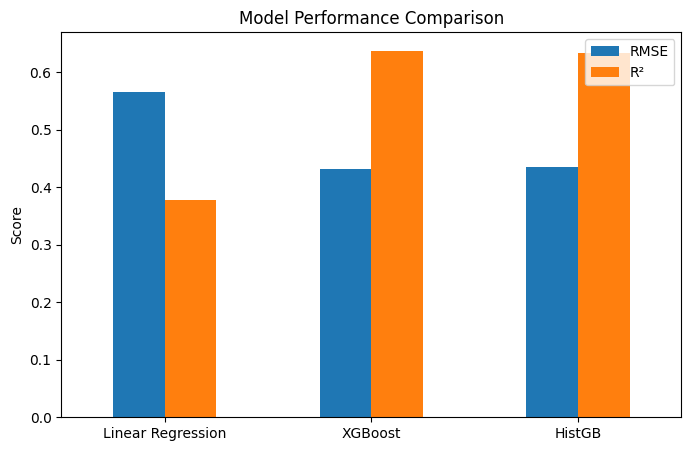

In [55]:
metrics = {
    'Linear Regression': [rmse, r2],
    'XGBoost': [0.4316, 0.6372],
    'HistGB': [0.4344, 0.6325]
}

df_metrics = pd.DataFrame(metrics, index=['RMSE', 'R²']).T
df_metrics.plot(kind='bar', figsize=(8, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc='upper right')
plt.show()


#**Insight:**  
* XGBoost outperforms other models with the lowest RMSE and highest R². HistGradientBoosting is close, while Linear Regression lags behind.
* Linear regression explained only ~38% of price variation.
* XGBoost with tuned parameters (100 trees, depth 6, learning rate 0.1) gave the best performance.
* Advanced models like XGBoost and HistGradientBoosting can capture non-linear patterns and handle missing values more effectively.

#**Recommendation:**  
* Use XGBoost or HistGradientBoosting to improve accuracy.
* Apply feature selection to reduce noise and simplify the model for better generalization.
* Use XGBoost as your final model. It balances accuracy and interpretability, and handles non-linear relationships effectively.

